# 3 · 深度學習壓縮:AE / VAE(表格)+ CNN(影像概念)

統計法是固定公式;神經網路**學**壓縮。

- **AE**(表格):非線性瓶頸,重建最省維。
- **VAE**(表格):潛空間加 N(0,I) 先驗 → 可生成/採樣。
- **CNN**(影像):把整座城當高度影像,卷積讀空間紋理——**概念方向**(本資料量僅示範輸入,見下方誠實邊界)。

訓練完的**表格** AE/VAE 存檔到 `out/models/`,NB4/NB5 直接載入。

## 環境 + 兩種資料

In [6]:
import sys, os
from pathlib import Path
_here = Path(os.getcwd()).resolve()
_r07 = next((p for p in [_here, *_here.parents] if (p / 'nn').exists()), _here)
if str(_r07) not in sys.path: sys.path.insert(0, str(_r07))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
import nn                       # 建築層 + 中文字型自動修好
print('07 根:', _r07)
from nn import conv, io, raster

07 根: C:\baidunetdiskdownload\power_to_form\DF26_ws18\07_Latent_Urban


In [7]:
SLUG = 'lujiazui'
X, feat_names, aux = nn.make_dataset(SLUG)          # 表格
SLUGS = ['lujiazui','caoyang','yuyuan','waitan','nanjingxi','kongjiang',
         'pengpu','laoximen','dapuqiao','xujiahui','nanjingdong','beiwaitan']
Ximg, labels = raster.city_patch_dataset(SLUGS, patch=64, stride=16)  # 影像
print('表格', X.shape, '| 影像 patch', Ximg.shape)

表格 (3263, 16) | 影像 patch (993, 1, 64, 64)


## A. 表格 AE / VAE
訓練,看重建誤差。VAE loss 高於 AE 是正常的(多了 KL 正則,換來可生成)。

AE  recon MSE 0.0475  (最終loss 0.0475)
VAE recon MSE 0.3539  (最終loss 0.3538)


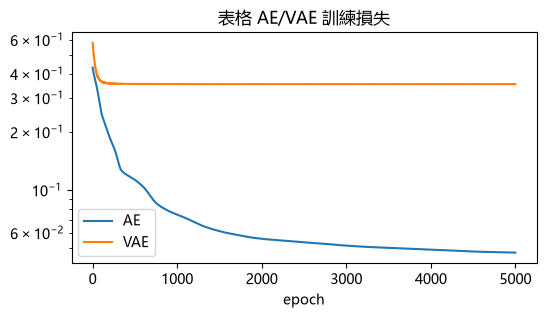

In [8]:
# 07 的 nn.train_ae(X) 會自建並回傳 (模型, 每回合loss);潛維由 config.LATENT_DIM(=2)決定
ae, ae_losses = nn.train_ae(X, epochs=5000)
vae, vae_losses = nn.train_vae(X, epochs=5000, beta=1.0)
ae_mse = ((ae.reconstruct(X) - X)**2).mean()
vae_mse = ((vae.reconstruct(X) - X)**2).mean()
print('AE  recon MSE %.4f  (最終loss %.4f)' % (ae_mse, ae_losses[-1]))
print('VAE recon MSE %.4f  (最終loss %.4f)' % (vae_mse, vae_losses[-1]))
fig, ax = plt.subplots(figsize=(6,3))
ax.plot(ae_losses, label='AE'); ax.plot(vae_losses, label='VAE')
ax.set_yscale('log'); ax.legend(); ax.set_xlabel('epoch'); ax.set_title('表格 AE/VAE 訓練損失'); plt.show()

## B. 影像視角:CNN 讀空間紋理(概念)
把整座城當成一張**高度影像**,用卷積(CNN)讀「街廓排列、疏密」——urban form 最自然的 NN 表示。

> **誠實邊界(重要)**:本專案只有 12 座城、且高度圖約 **86% 是空白**。資料量遠不足以訓練出能
> **清晰重建/生成**的影像 VAE(小資料 + 稀疏高頻 → 解碼器會塌成模糊)。因此這裡只示範 **CNN 的輸入影像**
> 與概念;真正可用的**壓縮/生成**請看上面的**表格 AE/VAE**。要做影像 CNN-VAE,需數千張以上的城市/街廓影像。

In [ ]:
# CNN 的輸入 = 城市高度 patch(挑非空的幾張看)
import numpy as np
fill = (Ximg > 0).reshape(len(Ximg), -1).mean(1)
pick = fill.argsort()[::-1][:6]
fig, ax = plt.subplots(1, 6, figsize=(13, 2.4)); fig.patch.set_facecolor('white')
for a, k in zip(ax, pick):
    a.imshow(Ximg[k, 0], cmap='inferno'); a.set_xticks([]); a.set_yticks([])
fig.suptitle('城市高度 patch:CNN 的輸入影像(卷積在這上面讀紋理)'); plt.show()
print('patch 數:', len(Ximg), '| 每張非空比例中位數 %.0f%%' % (np.median(fill)*100))

## C. 存檔:訓練一次,後續重用

In [11]:
# 存檔:訓練一次,後續 NB4/5 重用(只存能用的表格 AE/VAE)
io.save_model(ae,  'ae_lujiazui',  {'kind':'AE','input_dim':int(X.shape[1]),'latent':2,'slug':SLUG})
io.save_model(vae, 'vae_lujiazui', {'kind':'VAE','input_dim':int(X.shape[1]),'latent':2,'slug':SLUG})
print('已存到', io.MODELS); print(sorted(p.name for p in io.MODELS.glob('*.pt')))

已存到 C:\baidunetdiskdownload\power_to_form\DF26_ws18\07_Latent_Urban\out\models
['ae_lujiazui.pt', 'conv_vae.pt', 'vae_lujiazui.pt']


## 小結
- **AE**(表格)重建最省維;**VAE**(表格)換來可生成——這兩個是本專案真正能用的壓縮/生成。
- **CNN**:把城市當影像是很好的**概念方向**,但需要遠多於 12 城的影像資料才能訓練出清晰的重建/生成。
- 模型已存檔 → NB4 分析潛空間、NB5 生成都直接載入。
- NN 啟發:換**表示**(表格→影像)+ 換**架構**(MLP→CNN),同資料能學到不同層次;但**資料量**決定能走多遠。